# 03 · Análisis lingüístico mediante POS Tagging

Etiquetado gramatical del corpus del numeral 1 (`texto_crudo` en `datos/corpus.csv`) con spaCy y el modelo `es_core_news_sm`. Verdad y Falso se procesan por separado. El texto limpio no se usa: el etiquetado necesita mayúsculas, tildes y puntuación.

## 0. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = Path.cwd()
DATOS = BASE / "datos"
RESULTADOS = BASE / "resultados"
RESULTADOS.mkdir(exist_ok=True)

CATEGORIAS = ["NOUN", "VERB", "ADJ", "ADV", "PRON"]
TOKENS_PATH = RESULTADOS / "03_pos_tokens.csv"

pd.set_option("display.max_colwidth", 200)

corpus = pd.read_csv(DATOS / "corpus.csv", keep_default_na=False)
print(corpus.shape)
print(corpus["clase"].value_counts().to_string())

(5150, 8)
clase
Verdad    2575
Falso     2575


## 1. Etiquetado

Se ignoran la puntuación (`PUNCT`) y los espacios (`SPACE`). El porcentaje de cada categoría se calcula sobre el resto de tokens de esa clase. spaCy separa los nombres propios (`PROPN`) de `NOUN` y los auxiliares (`AUX`) de `VERB`; se cuentan aparte y no se suman. Se desactivan el parser y el NER porque esta sección solo necesita la etiqueta POS y el lema. Si `resultados/03_pos_tokens.csv` ya existe, se carga y no se vuelve a etiquetar.

In [2]:
if TOKENS_PATH.exists():
    tokens = pd.read_csv(TOKENS_PATH, keep_default_na=False)
    print(f"Cargado {TOKENS_PATH.name}: {len(tokens)} tokens")
else:
    import spacy

    nlp = spacy.load("es_core_news_sm")
    nlp.disable_pipes("parser", "ner")
    filas = []
    for clase in ["Verdad", "Falso"]:
        parte = corpus.loc[corpus["clase"] == clase, ["doc_id", "texto_crudo"]]
        documentos = nlp.pipe(parte["texto_crudo"].tolist(), batch_size=64)
        for doc_id, doc in zip(parte["doc_id"].tolist(), documentos):
            for token in doc:
                if token.pos_ in {"PUNCT", "SPACE"}:
                    continue
                filas.append((doc_id, clase, token.text, token.lemma_.lower(), token.pos_))
        print(clase, "etiquetada")
    tokens = pd.DataFrame(filas, columns=["doc_id", "clase", "token", "lema", "pos"])
    tokens.to_csv(TOKENS_PATH, index=False)
    print(f"Guardado {TOKENS_PATH.name}: {len(tokens)} tokens")

doc_id = corpus.loc[0, "doc_id"]
print()
print(doc_id, "·", corpus.loc[0, "clase"])
print(corpus.loc[0, "texto_crudo"])
tokens.loc[tokens["doc_id"] == doc_id, ["token", "lema", "pos"]].head(12)

Cargado 03_pos_tokens.csv: 281542 tokens

curado_2501 · Verdad
El 51% de los alemanes está en contra de la extradición de Puigdemont a España. Una encuesta de diario Die Welt revela que son los votantes de La Izquierda y de la ultraderecha los que más rechazan que el expresident de la Generalitat sea entregado a España, donde se le acusa de rebelión y malversación de fondos públicos


,token,lema,pos
0,El,el,DET
1,51%,51%,SYM
2,de,de,ADP
3,los,el,DET
4,alemanes,alemán,NOUN
5,está,estar,AUX
6,en,en,ADP
7,contra,contra,NOUN
8,de,de,ADP
9,la,el,DET


## 2. Frecuencia absoluta y relativa

La tabla siguiente es la del enunciado. Debajo quedan `PROPN` y `AUX`, que el modelo no incluye en `NOUN` ni en `VERB`.

In [3]:
conteo = tokens.groupby(["clase", "pos"]).size()
totales = tokens.groupby("clase").size()


def tabla_pos(categorias):
    filas = []
    for pos in categorias:
        verdad = int(conteo.get(("Verdad", pos), 0))
        falso = int(conteo.get(("Falso", pos), 0))
        filas.append({
            "POS": pos,
            "Verdaderas (cantidad)": verdad,
            "Verdaderas (%)": round(verdad / totales["Verdad"] * 100, 2),
            "Falsas (cantidad)": falso,
            "Falsas (%)": round(falso / totales["Falso"] * 100, 2),
        })
    return pd.DataFrame(filas)


tabla = tabla_pos(CATEGORIAS)
tabla.to_csv(RESULTADOS / "03_pos_tabla.csv", index=False)
print(
    "Tokens sin puntuación ni espacios: "
    f"Verdad {int(totales['Verdad'])} · Falso {int(totales['Falso'])}"
)
tabla

Tokens sin puntuación ni espacios: Verdad 139742 · Falso 141800


,POS,Verdaderas (cantidad),Verdaderas (%),Falsas (cantidad),Falsas (%)
0,NOUN,27684,19.81,27137,19.14
1,VERB,14039,10.05,13799,9.73
2,ADJ,8528,6.10,8502,6.00
3,ADV,3199,2.29,3152,2.22
4,PRON,4675,3.35,4383,3.09


In [4]:
otras = tabla_pos(["PROPN", "AUX"])
otras.to_csv(RESULTADOS / "03_pos_propn_aux.csv", index=False)
otras

,POS,Verdaderas (cantidad),Verdaderas (%),Falsas (cantidad),Falsas (%)
0,PROPN,18180,13.01,21625,15.25
1,AUX,3571,2.56,3506,2.47


## 3. Gráfico de barras

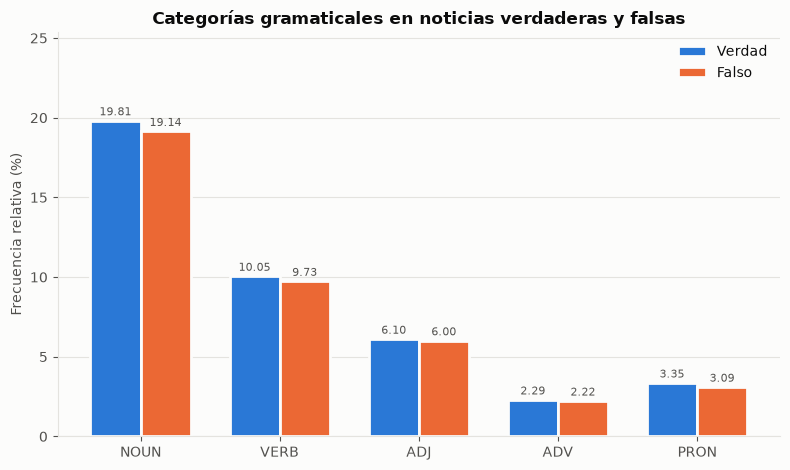

In [5]:
SUPERFICIE, TINTA, TINTA_2, CUADRICULA = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": CUADRICULA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "text.color": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": CUADRICULA, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

fig, ax = plt.subplots(figsize=(8, 4.8))
posiciones = np.arange(len(CATEGORIAS))
ancho = 0.36
barras_v = ax.bar(
    posiciones - ancho / 2, tabla["Verdaderas (%)"], ancho,
    label="Verdad", color="#2a78d6", edgecolor=SUPERFICIE, linewidth=2,
)
barras_f = ax.bar(
    posiciones + ancho / 2, tabla["Falsas (%)"], ancho,
    label="Falso", color="#eb6834", edgecolor=SUPERFICIE, linewidth=2,
)
ax.bar_label(barras_v, fmt="%.2f", padding=2, fontsize=8, color=TINTA_2)
ax.bar_label(barras_f, fmt="%.2f", padding=2, fontsize=8, color=TINTA_2)
ax.set_xticks(posiciones, CATEGORIAS)
ax.set_ylabel("Frecuencia relativa (%)")
ax.set_title("Categorías gramaticales en noticias verdaderas y falsas")
ax.legend(frameon=False)
ax.set_ylim(0, tabla[["Verdaderas (%)", "Falsas (%)"]].to_numpy().max() * 1.28)
plt.tight_layout()
plt.savefig(RESULTADOS / "03_pos_barras.png", dpi=150)
plt.show()

## 4. Diez lemas más frecuentes

Sustantivos, verbos y adjetivos, agrupados por lema en minúsculas: «aprobó» y «aprobar» cuentan como la misma palabra. En las falsas, «vers» y «ver» son el mismo fragmento de «Iniciativa vers per Catalunya»; el lematizador lo parte de dos formas y lo etiqueta como sustantivo.

In [6]:
from IPython.display import display


def top_lemas(clase, pos, n=10):
    return (
        tokens.loc[
            (tokens["clase"] == clase) & (tokens["pos"] == pos) & tokens["lema"].str.isalpha(),
            "lema",
        ]
        .value_counts()
        .head(n)
        .rename_axis("lema")
        .reset_index(name="frecuencia")
    )


bloques = []
for pos in ["NOUN", "VERB", "ADJ"]:
    for clase in ["Verdad", "Falso"]:
        parte = top_lemas(clase, pos)
        parte.insert(0, "puesto", range(1, len(parte) + 1))
        parte.insert(0, "clase", clase)
        parte.insert(0, "categoria", pos)
        bloques.append(parte)
top = pd.concat(bloques, ignore_index=True)
top.to_csv(RESULTADOS / "03_pos_top10.csv", index=False)

for pos in ["NOUN", "VERB", "ADJ"]:
    verdad = top.loc[(top["categoria"] == pos) & (top["clase"] == "Verdad"), ["puesto", "lema", "frecuencia"]]
    falso = top.loc[(top["categoria"] == pos) & (top["clase"] == "Falso"), ["lema", "frecuencia"]]
    vista = pd.concat(
        [
            verdad.reset_index(drop=True).rename(columns={"lema": "Verdad", "frecuencia": "Frecuencia verdad"}),
            falso.reset_index(drop=True).rename(columns={"lema": "Falso", "frecuencia": "Frecuencia falso"}),
        ],
        axis=1,
    )
    print(pos)
    display(vista)

NOUN


,puesto,Verdad,Frecuencia verdad,Falso,Frecuencia falso
0,1,partido,344,partido,440
1,2,presidente,296,vers,373
2,3,año,277,presidente,304
3,4,ley,186,líder,231
4,5,líder,178,año,224
5,6,elección,177,elección,213
6,7,caso,173,formación,196
7,8,juez,171,ley,195
8,9,acuerdo,166,ver,186
9,10,formación,146,acuerdo,173


VERB


,puesto,Verdad,Frecuencia verdad,Falso,Frecuencia falso
0,1,tener,362,tener,393
1,2,pedir,290,pedir,302
2,3,hacer,262,hacer,266
3,4,dar,188,asegurar,194
4,5,decir,180,dar,179
5,6,asegurar,171,decir,165
6,7,seguir,142,seguir,154
7,8,rechazar,118,anunciar,143
8,9,dejar,117,querer,140
9,10,poner,115,defender,123


ADJ


,puesto,Verdad,Frecuencia verdad,Falso,Frecuencia falso
0,1,nuevo,231,nuevo,222
1,2,primero,165,político,195
2,3,público,145,primero,158
3,4,político,141,electoral,141
4,5,general,125,público,123
5,6,electoral,113,general,121
6,7,próximo,107,último,117
7,8,último,99,próximo,102
8,9,social,94,social,90
9,10,autonómico,84,español,84


## 5. Análisis

¿Existen diferencias relevantes en el uso de categorías gramaticales entre noticias falsas y verdaderas?

- No en las cinco categorías pedidas. La diferencia más grande es la de los sustantivos: 19,81 % en verdaderas y 19,14 % en falsas.
- Verbos (10,05 % y 9,73 %), adjetivos (6,10 % y 6,00 %), adverbios (2,29 % y 2,22 %) y pronombres (3,35 % y 3,09 %) quedan a menos de medio punto.
- Los nombres propios, que spaCy cuenta como `PROPN` y no como `NOUN`, sí se separan: 15,25 % en falsas y 13,01 % en verdaderas.
- Los lemas más frecuentes son de política en las dos clases: partido, presidente, ley, tener, pedir, nuevo. En las falsas, «vers» y «ver» salen entre los sustantivos porque el modelo parte «Iniciativa vers per Catalunya», un nombre alterado de las noticias fabricadas.
- La gramática de las dos clases es la de un titular político. La diferencia visible está en los nombres propios y en algunas palabras concretas, no en el reparto de sustantivos, verbos, adjetivos, adverbios y pronombres.